### ELM264 İşaretler ve Sistemler – Proje 1

#### Sevde Betül Öztürk

##### SORU 1

Bu soruda bize iki adet karmaşık üstel işaret verilmiştir: x 
1
​
 (t)=e 
−(0.3+j1.2)t
  ve x 
2
​
 (t)=(t+1) 
0.5
 e 
−j0.5πt
 . Karmaşık değerli işaretler tek bir reel eksende doğrudan görselleştirilemediği için Euler özdeşliğinden yola çıkılarak dört farklı bileşene ayrılmaları gerekir.

Reel kısım Re{x(t)} ve sanal kısım Im{x(t)} işaretin kartezyen koordinatlardaki bileşenlerini; genlik ∣x(t)∣ ve faz ∠x(t) ise kutupsal koordinatlardaki büyüklük ve açı bileşenlerini temsil eder. Aralarındaki ilişki x(t)=∣x(t)∣e 
j∠x(t)
 =Re{x(t)}+jIm{x(t)} şeklindedir.

1a şıkkı için x 
1
​
 (t) üstel açılımla e 
−0.3t
 [cos(1.2t)−jsin(1.2t)] formuna gelir. Burada e 
−0.3t
  çarpanı genliği üstel olarak söndürürken, 1.2t argümanlı kosinüs ve sinüs terimleri reel ve sanal kısımlarda salınım üretir.

1b şıkkı için x 
2
​
 (t) açılımla  
t+1
​
 [cos(0.5πt)−jsin(0.5πt)] olur. Karekök terimi nedeniyle işaret yalnızca t≥−1 aralığında tanımlıdır; bu yüzden zaman ekseni bu noktadan başlatılmalıdır.

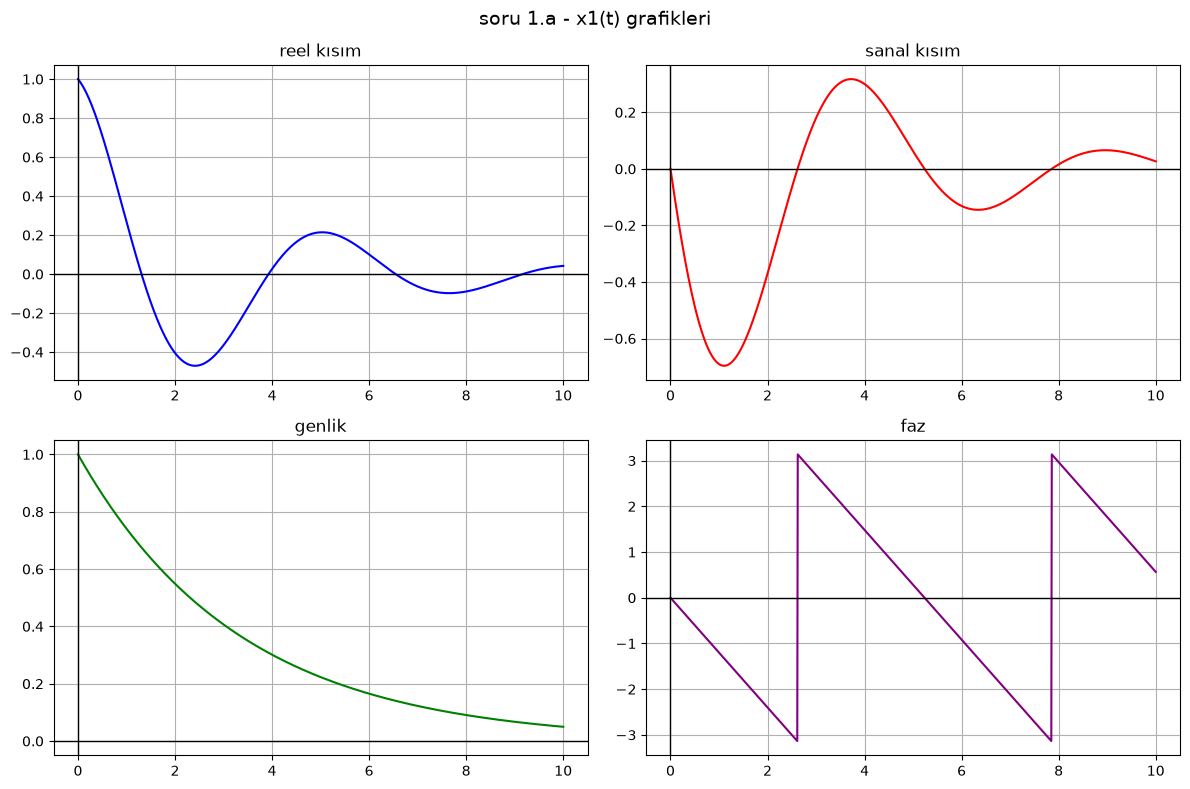

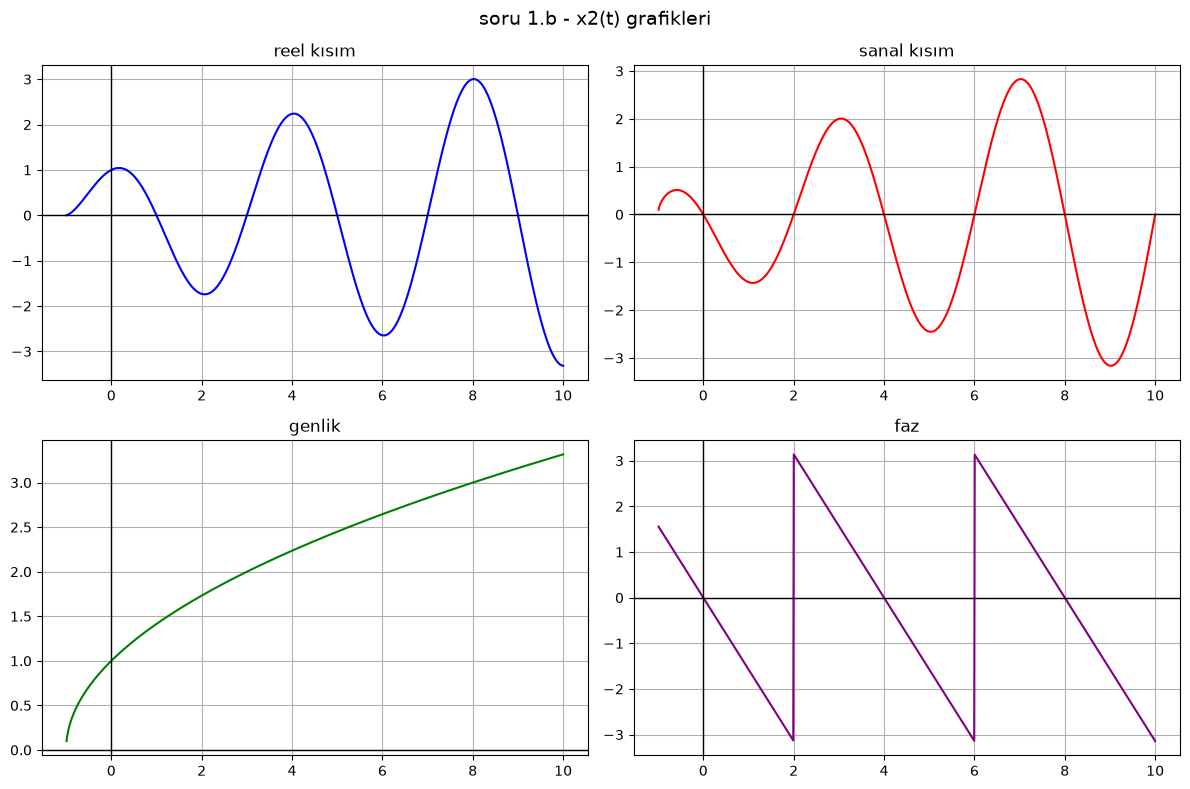

In [1]:
import numpy as np                   # sayısal hesaplamalar (kompleks sayı, üstel, trigonometrik fonksiyonlar) için
import matplotlib.pyplot as plt      # grafik çizimleri için

# t eksenini tanımlayalım, 0'dan 10'a yeterli olur
# 1000 nokta ile sürekli bir görüntü elde edecek kadar yoğun örnekleme yapıyoruz
t = np.linspace(0, 10, 1000)

# a şıkkı: x1(t) = e^(-(0.3 + j1.2)t)
#e^(a+jb)t = e^(at)[cos(bt)+jsin(bt)]
x1 = np.exp(-(0.3 + 1.2j) * t)

# b şıkkındaki işarette (t+1) in karekökü var. 
# t'yi -1 den küçük alırsak kök içi negatif olur
t_b = np.linspace(-0.99, 10, 1000)
# (t+1)**0.5 → karekök, np.exp(-1j*0.5*pi*t) → saf sanal üstel (genliği 1, fazı -0.5*pi*t)
x2 = (t_b + 1)**0.5 * np.exp(-1j * 0.5 * np.pi * t_b)

# 4 tane grafiği reel, sanal, genlik, faz her seferinde tekrar tekrar yazmak yerine tek fonksiyon ile yapacğım
# Bu sayede hem 1a hem 1b için aynı kodu tekrar yazmamış oluyoruz
def grafikleri_ciz(t_val, x_val, baslik):
    plt.figure(figsize=(12, 8))      
    plt.suptitle(baslik, fontsize=14)  # tüm figüre genel başlık ekle
    
    # reel kısım buraya
    # np.real() fonksiyonu kompleks sayının a+jb formundaki 'a' bileşenini döndürür
    plt.subplot(2, 2, 1)             # 2 satır 2 sütunluk grid'in 1. hücresi
    plt.plot(t_val, np.real(x_val), color='blue')
    plt.axhline(0, color='black', linewidth=1)   # x ekseni (y=0 doğrusu) referans için
    plt.axvline(0, color='black', linewidth=1)   # y ekseni (x=0 doğrusu) referans için
    plt.title('reel kısım')
    plt.grid(True)                  
    
    # sanal kısmı ayıralım
    # np.imag() fonksiyonu kompleks sayının a+jb formundaki 'b' bileşenini döndürür
    plt.subplot(2, 2, 2)
    plt.plot(t_val, np.imag(x_val), color='red')
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.title('sanal kısım')
    plt.grid(True)
    
    # genlik 
    # np.abs() kompleks sayının modülünü hesaplar: |a+jb| = sqrt(a^2 + b^2)
    plt.subplot(2, 2, 3)
    plt.plot(t_val, np.abs(x_val), color='green')
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.title('genlik')
    plt.grid(True)
    
    # faz kısmı angle ile alıyoruz
    # np.angle() kompleks sayının açısını verir: atan2(b,a), sonuç [-pi, pi] aralığındadır
    # Bu yüzden faz lineer azalsa bile grafikte testere dişi (sıçramalı) görünür
    plt.subplot(2, 2, 4)
    plt.plot(t_val, np.angle(x_val), color='purple')
    plt.title('faz')
    plt.grid(True)
    plt.tight_layout()               # alt grafiklerin birbirine girmesini engeller
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.show()
    
    
# a şıkkını çizdiriyoruz
grafikleri_ciz(t, x1, 'soru 1.a - x1(t) grafikleri')
# b şıkkını çizdiriyoruz
grafikleri_ciz(t_b, x2, 'soru 1.b - x2(t) grafikleri')

##### SORU 2:

Bu soruda bağımsız değişken üzerindeki temel zaman dönüşümleri incelenmektedir. Bize verilen x(t) işareti [−1,0) aralığında doğrusal artan, [0,2) aralığında sabit 1 değerinde, [2,3] aralığında doğrusal azalan ve diğer her yerde sıfır olan parçalı bir trapezoid (yamuk) işarettir.

İşaret dönüşümlerinde temel kural şudur: x(at+b) formundaki bir dönüşümde önce ölçekleme (a), sonra kaydırma (b) uygulanırsa kafa karışıklığı yaşanmaz. Alternatif olarak b yerine b/a ile kaydırma sonra a ile ölçekleme yapılabilir.

a) x(2t): Zamanda 2 kat sıkışma (daralma). Orijinal [−1,3] desteği [−0.5,1.5] aralığına sıkışır. Tüm karakteristik noktalar yarıya iner.

b) x(t−2): Zamanda 2 birim sağa kaydırma (gecikme). Destek [1,5] aralığına ötelenir, şekil aynen korunur.

c) x(−t+1): Önce zamanı ters çevirme (y-eksenine göre yansıma), sonra 1 birim sağa kaydırma. Destek [−2,2] aralığına gelir, ayrıca eğimler de ters döner (artan kısım azalan, azalan kısım artan olur).

d) x(0.5t+1): Zamanda 2 kat genişleme ve sola kaydırma. Destek [−4,4] aralığına yayılır, işaret iki kat uzar.

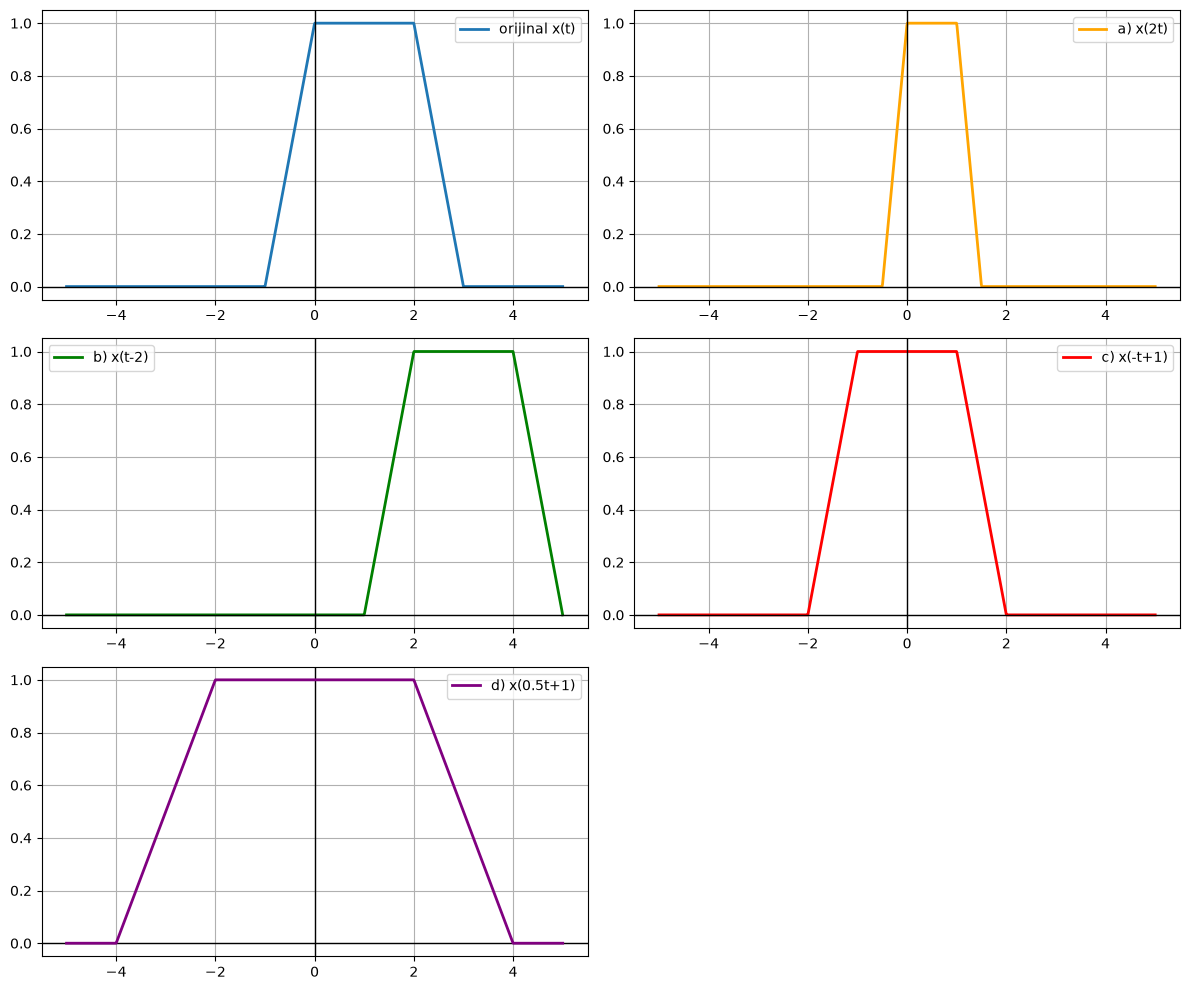

In [2]:
# x(t) yi tanımlayalım, parçalı fonksiyon olduğu için list comprehension kullanılır
# if else ile ayırdım
# Fonksiyonel yaklaşım: bir t dizisi alır, her elemanı için doğru parçayı seçer ve numpy dizisi döndürür
def x_fonksiyonu(t_dizisi):
    return np.array([
        (deger + 1) if -1 <= deger < 0 else      # 1. parça: t+1 doğrusu, [-1, 0) aralığında
        1 if 0 <= deger < 2 else                  # 2. parça: sabit 1, [0, 2) aralığında
        (-deger + 3) if 2 <= deger <= 3 else      # 3. parça: -t+3 doğrusu, [2, 3] aralığında
        0                                         # diğer her yerde işaret sıfır
        for deger in t_dizisi
    ])

# t aralığını -5 ten 5 e kadar verdim
# Tüm dönüşümlerin destek aralığını kapsayacak kadar geniş seçtik (özellikle x(0.5t+1) ±4'e kadar uzanıyor)
t = np.linspace(-5, 5, 1000)

# referans işaretimiz
# Karşılaştırma için orijinal x(t)'yi de hesaplayıp çiziyoruz
x_orijinal = x_fonksiyonu(t)

# şimdi şıklardaki dönüşümleri yapıyoruz
# a) zamanı 2 kat hızlandırıyoruz daralma olacak
# Fonksiyona t yerine 2t veriyoruz → yatayda 1/2 oranında sıkışma
x_a = x_fonksiyonu(2 * t)

# b) 2 birim sağa öteliyoruz gecikme var
# Fonksiyona t yerine (t-2) veriyoruz → yatayda 2 birim sağa kaydırma
x_b = x_fonksiyonu(t - 2)

# c) hem tersini alıyoruz hem 1 birim öteliyoruz
# Fonksiyona (-t+1) veriyoruz → önce y-eksenine göre yansıma sonra 1 birim sağa
x_c = x_fonksiyonu(-t + 1)

# d) zamanı yarıya düşürüp 1 birim kaydırıyoruz 
# Fonksiyona (0.5t+1) veriyoruz → 2 kat genişleme + sola kaydırma
x_d = x_fonksiyonu((1/2) * t + 1)

# hepsini alt alta yan yana şık bi şekilde tek figürde toplayalım
# 3x2 grid: 5 grafik (orijinal + 4 dönüşüm) toplam 6 hücreden 5'ini kullanacak
plt.figure(figsize=(12, 10))

plt.subplot(3, 2, 1)                                            # 1. hücre: orijinal işaret
plt.plot(t, x_orijinal, label='orijinal x(t)', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True); plt.legend()

plt.subplot(3, 2, 2)                                            # 2. hücre: a şıkkı
plt.plot(t, x_a, label='a) x(2t)', color='orange', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True); plt.legend()

plt.subplot(3, 2, 3)                                            # 3. hücre: b şıkkı
plt.plot(t, x_b, label='b) x(t-2)', color='green', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True); plt.legend()

plt.subplot(3, 2, 4)                                            # 4. hücre: c şıkkı
plt.plot(t, x_c, label='c) x(-t+1)', color='red', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True); plt.legend()

plt.subplot(3, 2, 5)                                            # 5. hücre: d şıkkı
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.plot(t, x_d, label='d) x(0.5t+1)', color='purple', linewidth=2)
plt.grid(True); plt.legend()

plt.tight_layout()                                              # alt grafikler arası boşluğu otomatik ayarla
plt.show()

##### SORU 3:

Sinyal teorisinde önemli bir sonuç şudur: herhangi bir reel işaret, çift ve tek bileşenlerinin toplamı olarak benzersiz şekilde ifade edilebilir.

Çift işaret tanımı: x 
e
​
 (−t)=x 
e
​
 (t) — y-eksenine göre simetrik (ayna görüntüsü). Tek işaret tanımı: x 
o
​
 (−t)=−x 
o
​
 (t) — orijine göre simetrik (180° dönüş simetrisi).

Bu ayrışım için kullanılan formüller:

x 
e
​
 (t)= 
2
x(t)+x(−t)
​
 ,x 
o
​
 (t)= 
2
x(t)−x(−t)
​
 

Doğrulama: x 
e
​
 (t)+x 
o
​
 (t)= 
2
x(t)+x(−t)
​
 + 
2
x(t)−x(−t)
​
 =x(t) ✓

soruda kullanılan trapezoid işaret simetrik olmadığı için hem çift hem tek bileşen sıfırdan farklı olacaktır. Çift kısım, orijinal şeklin hem kendisini hem ayna görüntüsünü içeren simetrik bir profil verir; tek kısım ise pozitif tarafta orijinalin yarısı kadar pozitif, negatif tarafta ise aynı yarının negatif yansımasını içerir.

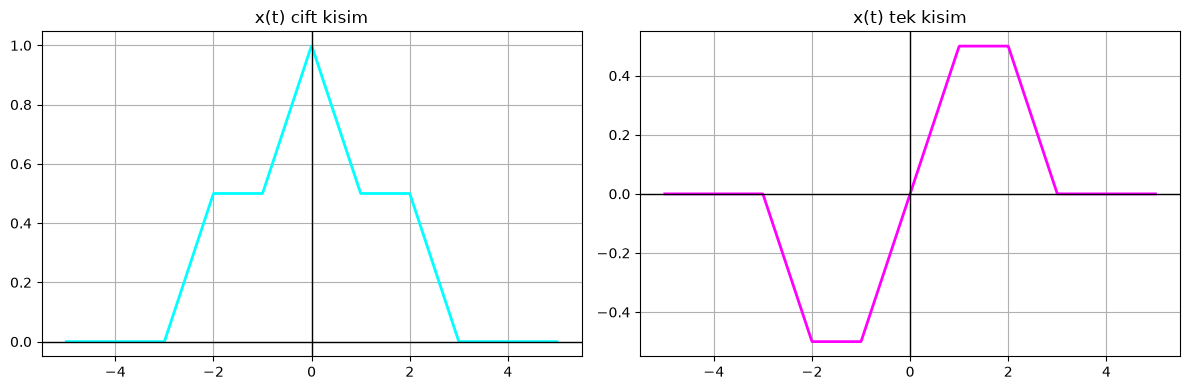

In [3]:
# yine 2. sorudaki aynı fonksiyonu kullanıyoruz
# Notebook bağımsız çalışsın diye fonksiyonu burada da tanımlıyoruz
def x_fonksiyonu(t_dizisi):
    return np.array([
        (deger + 1) if -1 <= deger < 0 else
        1 if 0 <= deger < 2 else
        (-deger + 3) if 2 <= deger <= 3 else
        0
        for deger in t_dizisi
    ])
# Simetri analizi için zaman ekseninin sıfır etrafında simetrik olması önemli
t = np.linspace(-5, 5, 1000)

# formülü uygulamak için işaretin normal halini ve zamanda ters çevrilmiş halini alıyoruz
# x_normal: x(t) — fonksiyona t değerlerini olduğu gibi veriyoruz
# x_ters: x(-t) — fonksiyona t yerine -t veriyoruz, bu y-eksenine göre yansıma demek
x_normal = x_fonksiyonu(t)
x_ters = x_fonksiyonu(-t)

# çift kısım formülü: (x(t) + x(-t)) / 2
# İki simetrik olmayan parçanın ortalaması her zaman çift simetrili bir sonuç verir
x_cift = (x_normal + x_ters) / 2

# tek kısım formülü: (x(t) - x(-t)) / 2
# x(t)'den x(-t)'nin çıkarılıp 2'ye bölünmesi tek simetrili bir sonuç üretir
x_tek = (x_normal - x_ters) / 2

# 1 satır 2 sütun grid: solda çift, sağda tek kısım
plt.figure(figsize=(12, 4))

# çift kısmın grafiği
plt.subplot(1, 2, 1)
plt.plot(t, x_cift, color='cyan', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.title('x(t) cift kisim')
plt.grid(True)

# tek kısmın grafiği
plt.subplot(1, 2, 2)
plt.plot(t, x_tek, color='magenta', linewidth=2)
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.title('x(t) tek kisim')
plt.grid(True)

plt.tight_layout()
plt.show()

##### SORU 4:

Sürekli zamanlı konvolüsyon integrali:

y(t)=∫ 
−∞
∞
​
 x(τ)h(t−τ)dτ

Bu integrali sayısal olarak yaklaşık hesaplamak için Riemann toplamı kullanırız. Yani dτ yerine küçük bir adım aralığı Δt alırız ve integrali toplama dönüştürürüz:

y[n]≈Δt⋅ 
k
∑
​
 x[k]h[n−k]

Δt ile çarpım, ayrık toplamı sürekli integrale yaklaştıran kritik adımdır — atlanırsa sonuç ölçek olarak yanlış çıkar. Algoritmik olarak iki iç içe döngü kuruyoruz: dış döngü çıkış zamanı n üzerinde, iç döngü ise τ değişkenine karşılık gelen k üzerinde gezer. Her n için h dürtü cevabını kaydırıp x ile noktasal çarpım yapıp toplayarak çıkışın o anki değerini elde ederiz.

a şıkkı analizi: x(t)=e 
−t
 u(t) üstel olarak sönen bir işaret, h(t)=u(t+1)−u(t−1) ise [−1,1] aralığında 1 değerindeki bir dikdörtgen darbedir. Konvolüsyon, üstel işaretin dikdörtgen pencereyle yumuşatılmış (smoothing) hali olarak çıkar — sonuç t=−1'den itibaren yükselip t=1 civarında tepe yaparak üstel sönüme geçer.

b şıkkı analizi: x(t)=sin(πt)[u(t)−u(t−2)] tek bir tam sinüs dalgasıdır (0 ile 2 arasında bir pozitif yarım dönem ve bir negatif yarım dönem içerir). h(t)=e 
−0.5t
 u(t) ise üstel sönen bir dürtü cevabıdır. Çıkış, sinüs dalgasının üstel sistem tarafından filtrelenmiş halidir; ilk yarıda pozitif tepe, sonra negatife geçiş ve uzun bir üstel kuyruk ile sönüm gözlenir.

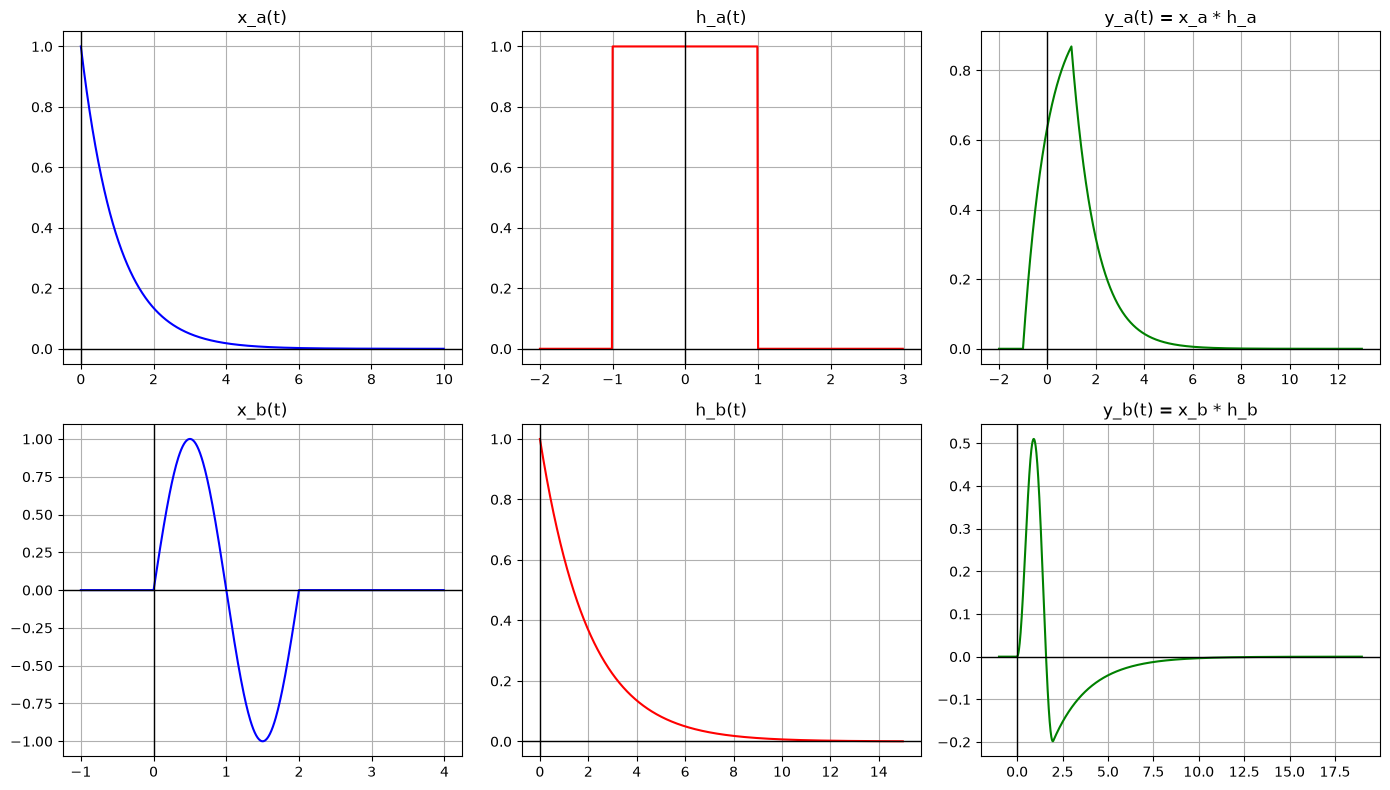

In [4]:
# dt ile çarpma kısmına dikkat etmemiz lazım.
# Ayrık toplamı sürekli integrale dönüştüren faktör dt'dir, unutulursa sonucun genliği yanlış çıkar
def kendi_konvolusyonum(x, h, dt):
    uzunluk_x = len(x)               # giriş işaretinin örnek sayısı (N)
    uzunluk_h = len(h)               # dürtü cevabının örnek sayısı (M)
    # konvolüsyon sonucunun toplam boyutu = M + N - 1
    # Bu ayrık konvolüsyonun standart matematiksel sonucudur (örtüşme bölgelerinin toplam sayısı)
    uzunluk_y = uzunluk_x + uzunluk_h - 1
    y = np.zeros(uzunluk_y)          # çıkış dizisini sıfırlarla başlat
    
    # iç içe döngüyle kaydırmalı çarpım yapıyoruz
    # t aralıklarını çok küçük almamız lazım bu yüzden dt:0.1 aldım
    # Dış döngü: çıkışın her bir n indeksi için (yani her bir t değeri için)
    for n in range(uzunluk_y):
        # İç döngü: konvolüsyon toplamının her bir terimini hesaplamak için k indeksi
        for k in range(uzunluk_x):
            # h(n-k) sınırların içinde kalıyor mu kontrolü
            # Bu kontrol yapılmazsa dizi sınırı dışına çıkıp hata alırız
            # Sınır içindeyse x[k]*h[n-k] çarpımını birikimli toplama ekle
            if 0 <= n - k < uzunluk_h:
                y[n] += x[k] * h[n - k]
    return y * dt                    # son adımda dt ile çarp → integral yaklaşımını tamamla

# dt: zaman örnekleme adımı. Küçük olursa sonuç hassas, ama hesap yavaş olur. 0.01 iyi bir denge.
dt = 0.01

# a şıkkı: x(t) = e^(-t)u(t) ve h(t) = u(t+1) - u(t-1)
# t eksenlerini tanımlıyoruz, u(t) olduğu için x(t) 0'dan başlıyor
# u(t) birim basamak fonksiyonu t<0 için 0, t>=0 için 1 olduğundan x(t) sadece t>=0 için anlamlı
t_x_a = np.arange(0, 10, dt) 
x_a = np.exp(-t_x_a)             # t>=0 olduğu için u(t) zaten 1 olur, ayrıca çarpmaya gerek yok

# h(t) için zaman ekseni: -2'den 3'e kadar geniş alındı (h'nin desteği -1 ile 1 arası ama güvenli pay bırakıldı)
t_h_a = np.arange(-2, 3, dt)
# u(t+1) - u(t-1) demek -1 ile 1 arasında 1 olan kare dalga demek
# np.where(koşul, doğruysa, yanlışsa) ile dikdörtgen pencereyi oluşturuyoruz
h_a = np.where((t_h_a >= -1) & (t_h_a < 1), 1.0, 0.0)

# sonucun zaman ekseni sınırların toplamı kadar olacak
# Konvolüsyonun temel özelliği: y(t)'nin desteği = x(t) desteği + h(t) desteği (Minkowski toplamı)
# Yani başlangıç = t_x_a[0] + t_h_a[0], bitiş = t_x_a[-1] + t_h_a[-1]
t_y_a = np.arange(t_x_a[0] + t_h_a[0], t_x_a[-1] + t_h_a[-1] + dt, dt)

y_a = kendi_konvolusyonum(x_a, h_a, dt)   # manuel konvolüsyonu çağır

# float hassasiyeti yüzünden dizilerde bazen 1 elemanlık fark çıkıyor
# hata vermesin diye dizileri minimum boyuta kırpıyoruz
# np.arange'in float aritmetiği bazen beklenenden 1 eleman fazla/eksik üretebilir, bu güvenlik önlemi
min_boyut_a = min(len(t_y_a), len(y_a))
t_y_a = t_y_a[:min_boyut_a]
y_a = y_a[:min_boyut_a]

# b şıkkı: x(t) = sin(pi*t)[u(t)-u(t-2)] ve h(t) = e^(-0.5t)u(t)
# x(t) için zaman ekseni: -1'den 4'e kadar (asıl destek 0 ile 2 arası, etrafına pay bırakıldı)
t_x_b = np.arange(-1, 4, dt)
# sin(pi*t) ile pencereyi çarp: pencere [u(t)-u(t-2)] sadece [0,2]'de 1 değerini alır
x_b = np.sin(np.pi * t_x_b) * np.where((t_x_b >= 0) & (t_x_b < 2), 1.0, 0.0)

# h(t) için zaman ekseni: 0'dan 15'e kadar (üstel sönüm pratikte bu süre içinde sıfıra yaklaşır)
# t=15'te e^(-7.5) ≈ 0.00055 olduğu için bu kesim güvenli
t_h_b = np.arange(0, 15, dt)
h_b = np.exp(-0.5 * t_h_b)

# Yine konvolüsyon çıkışı için zaman ekseni
t_y_b = np.arange(t_x_b[0] + t_h_b[0], t_x_b[-1] + t_h_b[-1] + dt, dt)

y_b = kendi_konvolusyonum(x_b, h_b, dt)

# Aynı boyut kırpma güvenliği b şıkkı için de uygulanıyor
min_boyut_b = min(len(t_y_b), len(y_b))
t_y_b = t_y_b[:min_boyut_b]
y_b = y_b[:min_boyut_b]

# görselleri çizdirme fonksiyonumuz
# 2x3 grid: üst satır a şıkkı (x, h, y), alt satır b şıkkı (x, h, y)
plt.figure(figsize=(14, 8))

# a şıkkının plotları
plt.subplot(2, 3, 1)                 # üst-sol: a şıkkının giriş işareti
plt.plot(t_x_a, x_a, 'b'); plt.title('x_a(t)')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

plt.subplot(2, 3, 2)                 # üst-orta: a şıkkının dürtü cevabı
plt.plot(t_h_a, h_a, 'r'); plt.title('h_a(t)')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

plt.subplot(2, 3, 3)                 # üst-sağ: a şıkkının konvolüsyon çıkışı
plt.plot(t_y_a, y_a, 'g'); plt.title('y_a(t) = x_a * h_a')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

# b şıkkının plotları
plt.subplot(2, 3, 4)                 # alt-sol: b şıkkının giriş işareti
plt.plot(t_x_b, x_b, 'b'); plt.title('x_b(t)')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

plt.subplot(2, 3, 5)                 # alt-orta: b şıkkının dürtü cevabı
plt.plot(t_h_b, h_b, 'r'); plt.title('h_b(t)')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

plt.subplot(2, 3, 6)                 # alt-sağ: b şıkkının konvolüsyon çıkışı
plt.plot(t_y_b, y_b, 'g'); plt.title('y_b(t) = x_b * h_b')
plt.axhline(0, color='black', linewidth=1); plt.axvline(0, color='black', linewidth=1)
plt.grid(True)

plt.tight_layout()
plt.show()